# Mô hình dự đoán điểm đánh giá của khách hàng (Olist)

## 1. Mục tiêu
Notebook này xây dựng mô hình học máy **nhận diện các đơn hàng có nguy cơ nhận điểm đánh giá thấp (1–2 sao)** từ dữ liệu đơn hàng Olist (Brazil, 2016–2018), đồng thời chỉ ra các yếu tố vận hành (thời gian giao, số mặt hàng, phí vận chuyển...) liên quan nhiều nhất đến điểm đánh giá.

Vì điểm đánh giá lệch mạnh (59% là 5 sao, chỉ ~13% là 1–2 sao), bài toán chính được đặt dạng **phân loại nhị phân** (điểm thấp ≤ 2 hay không). Bài toán 5 lớp (điểm 1–5) chỉ dùng để tham khảo.

## 2. Dữ liệu
- Nguồn: cơ sở dữ liệu SQLite `data/olist.db`, truy vấn qua 2 view được định nghĩa trong `sql/03_queries.sql`.
- Mỗi dòng là **1 đơn hàng đã giao có review** (95.329 đơn), nhãn là `review_score`.
- Hai kịch bản feature, tách riêng để tránh rò rỉ dữ liệu (data leakage):
  - `v_model_features_at_purchase`: chỉ dùng thông tin biết **lúc đặt hàng** (giờ/tháng mua, bang, số mặt hàng, giá, phí ship, thanh toán...).
  - `v_model_features_post_delivery`: bổ sung thông tin **sau khi giao** (`delivery_days`, `estimated_days`, `delay_days`, `is_late`, `same_state_item_pct`).

## 3. Công cụ sử dụng
| Công cụ | Vai trò |
|---|---|
| `sqlite3` + SQL | Kết nối `olist.db`, đọc 2 view feature |
| `pandas`, `numpy` | Nạp, kiểm tra, xử lý dữ liệu và tính toán |
| `scikit-learn` | Chia train/test, tiền xử lý (`ColumnTransformer`, `OneHotEncoder`, `StandardScaler`), mô hình (Logistic Regression, Random Forest, HistGradientBoosting), tinh chỉnh (`RandomizedSearchCV`), đánh giá (ROC-AUC, PR-AUC, F1, confusion matrix, permutation importance) |
| `scipy` | Phân phối ngẫu nhiên cho bước tìm tham số |
| `matplotlib` | Vẽ confusion matrix và biểu đồ feature importance |
| `joblib` | Lưu mô hình đã huấn luyện |

## 4. Quy trình
1. Nạp dữ liệu và kiểm tra chất lượng
2. Chia train/test và tạo baseline
3. Huấn luyện 3 mô hình trên feature lúc đặt hàng
4. Thêm feature sau giao hàng và so sánh
5. Chọn ngưỡng phân loại, đọc confusion matrix, xem feature importance
6. Tinh chỉnh tham số và loại bỏ feature yếu
7. Chốt mô hình, lưu file, dự đoán thử

## 5. Lưu ý về cách đánh giá
- **Không dùng accuracy làm thước đo chính**: model luôn đoán "bình thường" đã đạt ~87% accuracy. Các thước đo chính là **ROC-AUC, PR-AUC và F1 của lớp điểm thấp**.
- Ngưỡng phân loại được chọn trên tập **validation** tách từ tập train, tập test chỉ dùng để đánh giá cuối.

## Bước 0. Khai báo thư viện

In [1]:
# Hệ thống & xử lý dữ liệu
import sqlite3
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import randint

# scikit-learn: chia dữ liệu, tiền xử lý, mô hình, đánh giá
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, average_precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

## Bước 1. Nạp dữ liệu và kiểm tra chất lượng
Kết nối `olist.db` bằng `sqlite3`, tự tạo 2 view feature từ `03_queries.sql` nếu chưa có, rồi nạp vào `pandas`. Sau đó kiểm tra kích thước, kiểu dữ liệu, phân bố nhãn, giá trị thiếu và `order_id` trùng.

In [2]:
# Thư mục gốc dự án = 2 cấp trên notebook này
ROOT = Path("../..").resolve()
DB_PATH  = ROOT / "data" / "olist.db"
SQL_PATH = ROOT / "sql" / "03_queries.sql"

print("DB tồn tại:", DB_PATH.exists(), "| SQL tồn tại:", SQL_PATH.exists())

conn = sqlite3.connect(DB_PATH)

# Kiểm tra 2 view dành cho mô hình đã tồn tại chưa
views = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='view'", conn
)["name"].tolist()
print("Views hiện có:", views)

need = {"v_model_features_at_purchase", "v_model_features_post_delivery"}
if not need.issubset(views):
    print("Thiếu view -> chạy 03_queries.sql để tạo...")
    with open(SQL_PATH, encoding="utf-8") as f:
        conn.executescript(f.read())

# Nạp 2 bộ feature (mỗi dòng = 1 đơn hàng đã giao có review)
df_pre  = pd.read_sql_query("SELECT * FROM v_model_features_at_purchase", conn)
df_post = pd.read_sql_query("SELECT * FROM v_model_features_post_delivery", conn)

print("\n--- at_purchase ---")
print(df_pre.shape)
print(df_pre.dtypes)

print("\n--- post_delivery ---")
print(df_post.shape)

print("\nPhân bố target (%):")
print((df_pre["target_review_score"].value_counts(normalize=True)
       .sort_index() * 100).round(2))

print("\nMissing values (at_purchase):")
print(df_pre.isna().sum()[df_pre.isna().sum() > 0])

print("\nMissing values (post_delivery):")
print(df_post.isna().sum()[df_post.isna().sum() > 0])

print("\nSố order_id trùng (kỳ vọng = 0):", df_pre["order_id"].duplicated().sum())
df_pre.head()

DB tồn tại: True | SQL tồn tại: True
Views hiện có: ['v_sales_monthly', 'v_delivery_kpi', 'v_category_performance', 'v_customer_rfm', 'v_seller_performance', 'v_payment_mix', 'v_review_order_features', 'v_model_features_at_purchase', 'v_model_features_post_delivery']

--- at_purchase ---
(95329, 16)
order_id                    str
target_review_score       int64
purchase_hour             int64
purchase_month            int64
customer_state              str
item_count                int64
distinct_products         int64
seller_count              int64
total_item_price        float64
total_freight           float64
freight_to_price_pct    float64
total_paid              float64
payment_count             int64
max_installments          int64
first_payment_type          str
voucher_value           float64
dtype: object

--- post_delivery ---
(95329, 21)

Phân bố target (%):
target_review_score
1     9.73
2     3.04
3     8.25
4    19.73
5    59.25
Name: proportion, dtype: float64

Missing 

,order_id,target_review_score,purchase_hour,purchase_month,customer_state,item_count,distinct_products,seller_count,total_item_price,total_freight,freight_to_price_pct,total_paid,payment_count,max_installments,first_payment_type,voucher_value
0,e481f51cbdc54678b7cc49136f2d6af7,4,10,10,SP,1,1,1,29.99,8.72,29.08,38.71,3,1,credit_card,20.59
1,53cdb2fc8bc7dce0b6741e2150273451,4,20,7,BA,1,1,1,118.70,22.76,19.17,141.46,1,1,boleto,0.00
2,47770eb9100c2d0c44946d9cf07ec65d,5,8,8,GO,1,1,1,159.90,19.22,12.02,179.12,1,3,credit_card,0.00
3,949d5b44dbf5de918fe9c16f97b45f8a,5,19,11,RN,1,1,1,45.00,27.20,60.44,72.20,1,1,credit_card,0.00
4,ad21c59c0840e6cb83a9ceb5573f8159,5,21,2,SP,1,1,1,19.90,8.72,43.82,28.62,1,1,credit_card,0.00


## Bước 2. Chia train/test và baseline
- Điền giá trị thiếu của `first_payment_type` bằng `"unknown"`.
- Chia 80/20 có phân tầng theo điểm 1–5, dùng chung một lần chia cho mọi mô hình để so sánh công bằng.
- Baseline (luôn đoán lớp phổ biến nhất) là mốc tối thiểu mà mô hình phải vượt.

In [3]:
# 1. Phân bố điểm đánh giá (kiểm tra mất cân bằng lớp)
vc = df_pre["target_review_score"].value_counts().sort_index()
print(pd.DataFrame({"so_don": vc, "ty_le_%": (vc / vc.sum() * 100).round(2)}))

# 2. Kiểm tra giá trị thiếu (chỉ in cột có thiếu)
for name, d in [("at_purchase", df_pre), ("post_delivery", df_post)]:
    m = d.isna().sum()
    print(f"\nMissing {name}:\n", m[m > 0] if (m > 0).any() else "Không có")

# 3. Xử lý giá trị thiếu: điền 'unknown' cho phương thức thanh toán
for d in (df_pre, df_post):
    d["first_payment_type"] = d["first_payment_type"].fillna("unknown")

# 4. Hai view phải cùng thứ tự đơn hàng để dùng chung 1 lần chia train/test
assert (df_pre["order_id"].values == df_post["order_id"].values).all()

# 5. Tách X (feature) và y (nhãn): y5 = điểm 1-5, y2 = nhị phân
y5 = df_pre["target_review_score"]
y2 = (y5 <= 2).astype(int)          # 1 = điểm thấp (1-2)

X_pre  = df_pre.drop(columns=["order_id", "target_review_score"])
X_post = df_post.drop(columns=["order_id", "target_review_score"])

# 6. Chia train/test 80/20 (stratify theo điểm 1-5), dùng chung cho mọi mô hình
idx_train, idx_test = train_test_split(
    df_pre.index, test_size=0.2, stratify=y5, random_state=42
)
print("\nTrain:", len(idx_train), "| Test:", len(idx_test))
print("Tỷ lệ điểm thấp - train: %.2f%% | test: %.2f%%"
      % (y2.loc[idx_train].mean() * 100, y2.loc[idx_test].mean() * 100))

# 7. Baseline: luôn đoán lớp phổ biến nhất (mốc tối thiểu mà mô hình phải vượt)
for label, y in [("5 lớp", y5), ("Nhị phân (thấp<=2)", y2)]:
    dummy = DummyClassifier(strategy="most_frequent")
    dummy.fit(X_pre.loc[idx_train], y.loc[idx_train])
    pred = dummy.predict(X_pre.loc[idx_test])
    print(f"\nBaseline {label}: accuracy = {accuracy_score(y.loc[idx_test], pred):.4f}"
          f" | macro-F1 = {f1_score(y.loc[idx_test], pred, average='macro'):.4f}")

                     so_don  ty_le_%
target_review_score                 
1                      9277     9.73
2                      2900     3.04
3                      7865     8.25
4                     18807    19.73
5                     56480    59.25

Missing at_purchase:
 first_payment_type    77
dtype: int64

Missing post_delivery:
 first_payment_type    77
dtype: int64

Train: 76263 | Test: 19066
Tỷ lệ điểm thấp - train: 12.77% | test: 12.77%

Baseline 5 lớp: accuracy = 0.5925 | macro-F1 = 0.1488

Baseline Nhị phân (thấp<=2): accuracy = 0.8723 | macro-F1 = 0.4659


## Bước 3. Huấn luyện 3 mô hình trên feature lúc đặt hàng (`at_purchase`)
So sánh Logistic Regression, Random Forest và HistGradientBoosting (đều dùng `class_weight` để bù mất cân bằng lớp) cho cả bài toán nhị phân và 5 lớp.

In [4]:
# Biến phân loại -> One-Hot; biến số -> giữ nguyên (LogReg có chuẩn hóa)
cat_cols = ["customer_state", "first_payment_type"]
num_cols = [c for c in X_pre.columns if c not in cat_cols]

def make_pre(scale):
    num = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("num", num, num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])

# 3 mô hình, đều dùng class_weight để bù mất cân bằng lớp
models = {
    "LogReg": Pipeline([("pre", make_pre(True)),
                        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "RandomForest": Pipeline([("pre", make_pre(False)),
                              ("clf", RandomForestClassifier(
                                  n_estimators=200, min_samples_leaf=20,
                                  class_weight="balanced_subsample",
                                  n_jobs=-1, random_state=42))]),
    "HistGB": Pipeline([("pre", make_pre(False)),
                        ("clf", HistGradientBoostingClassifier(
                            class_weight="balanced", random_state=42))]),
}

def run_all(X, tag):
    # Huấn luyện từng mô hình cho cả 2 bài toán (nhị phân và 5 lớp), đo trên tập test
    Xtr, Xte = X.loc[idx_train], X.loc[idx_test]
    rows = []
    for name, model in models.items():
        t0 = time.time()
        # --- Bài toán nhị phân: điểm thấp (<=2) ---
        model.fit(Xtr, y2.loc[idx_train])
        proba = model.predict_proba(Xte)[:, 1]
        pred = (proba >= 0.5).astype(int)
        yt = y2.loc[idx_test]
        bin_res = dict(
            roc_auc=roc_auc_score(yt, proba),
            pr_auc=average_precision_score(yt, proba),
            f1_low=f1_score(yt, pred),
            macro_f1_bin=f1_score(yt, pred, average="macro"),
        )
        # --- Bài toán 5 lớp ---
        model.fit(Xtr, y5.loc[idx_train])
        p5 = model.predict(Xte)
        multi_res = dict(
            macro_f1_5=f1_score(y5.loc[idx_test], p5, average="macro"),
            acc_5=accuracy_score(y5.loc[idx_test], p5),
        )
        rows.append({"data": tag, "model": name, **bin_res, **multi_res,
                     "sec": round(time.time() - t0, 1)})
        print(f"xong {name} ({rows[-1]['sec']}s)")
    return pd.DataFrame(rows).round(4)

res_pre = run_all(X_pre, "at_purchase")
res_pre

xong LogReg (1.9s)
xong RandomForest (6.7s)
xong HistGB (3.9s)


,data,model,roc_auc,pr_auc,f1_low,macro_f1_bin,macro_f1_5,acc_5,sec
0,at_purchase,LogReg,0.6181,0.2279,0.2750,0.5305,0.2202,0.3398,1.9
1,at_purchase,RandomForest,0.6470,0.2536,0.3056,0.5808,0.2305,0.3584,6.7
2,at_purchase,HistGB,0.6437,0.2569,0.2963,0.5522,0.2343,0.3569,3.9


## Bước 4. Thêm feature sau giao hàng (`post_delivery`)
Huấn luyện lại đúng 3 mô hình trên bộ feature có thêm thông tin giao hàng và so sánh mức cải thiện so với bước 3.

In [5]:
# Dựng lại pipeline theo cột của từng bộ feature (X_post có thêm cột giao hàng)
def build_models(X):
    cat = ["customer_state", "first_payment_type"]
    num = [c for c in X.columns if c not in cat]

    def pre(scale):
        return ColumnTransformer([
            ("num", StandardScaler() if scale else "passthrough", num),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
        ])

    return {
        "LogReg": Pipeline([("pre", pre(True)),
                            ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
        "RandomForest": Pipeline([("pre", pre(False)),
                                  ("clf", RandomForestClassifier(
                                      n_estimators=200, min_samples_leaf=20,
                                      class_weight="balanced_subsample",
                                      n_jobs=-1, random_state=42))]),
        "HistGB": Pipeline([("pre", pre(False)),
                            ("clf", HistGradientBoostingClassifier(
                                class_weight="balanced", random_state=42))]),
    }

print("Cột post_delivery:", list(X_post.columns))
print("Missing còn lại trong X_post:", int(X_post.isna().sum().sum()))

models = build_models(X_post)      # run_all đọc biến toàn cục `models`
res_post = run_all(X_post, "post_delivery")

# So sánh kịch bản lúc đặt hàng và sau giao hàng
cmp = pd.concat([res_pre, res_post], ignore_index=True)
print()
display(cmp)

delta = (res_post.set_index("model")[["roc_auc", "pr_auc", "f1_low", "macro_f1_bin", "macro_f1_5"]]
         - res_pre.set_index("model")[["roc_auc", "pr_auc", "f1_low", "macro_f1_bin", "macro_f1_5"]]).round(4)
print("\nMức tăng khi thêm thông tin giao hàng (post - pre):")
display(delta)

Cột post_delivery: ['purchase_hour', 'purchase_month', 'customer_state', 'item_count', 'distinct_products', 'seller_count', 'total_item_price', 'total_freight', 'freight_to_price_pct', 'total_paid', 'payment_count', 'max_installments', 'first_payment_type', 'voucher_value', 'delivery_days', 'estimated_days', 'delay_days', 'is_late', 'same_state_item_pct']
Missing còn lại trong X_post: 0
xong LogReg (3.1s)
xong RandomForest (10.1s)
xong HistGB (4.7s)



,data,model,roc_auc,pr_auc,f1_low,macro_f1_bin,macro_f1_5,acc_5,sec
0,at_purchase,LogReg,0.6181,0.2279,0.2750,0.5305,0.2202,0.3398,1.9
1,at_purchase,RandomForest,0.6470,0.2536,0.3056,0.5808,0.2305,0.3584,6.7
2,at_purchase,HistGB,0.6437,0.2569,0.2963,0.5522,0.2343,0.3569,3.9
3,post_delivery,LogReg,0.7539,0.4454,0.4540,0.6788,0.3034,0.4584,3.1
4,post_delivery,RandomForest,0.7523,0.4765,0.4715,0.6928,0.2970,0.4756,10.1
5,post_delivery,HistGB,0.7519,0.4817,0.4441,0.6696,0.2919,0.4424,4.7



Mức tăng khi thêm thông tin giao hàng (post - pre):


,roc_auc,pr_auc,f1_low,macro_f1_bin,macro_f1_5
model,,,,,
LogReg,0.1358,0.2175,0.1790,0.1483,0.0832
RandomForest,0.1053,0.2229,0.1659,0.1120,0.0665
HistGB,0.1082,0.2248,0.1478,0.1174,0.0576


## Bước 5. Chọn ngưỡng, confusion matrix và feature importance
Chọn Random Forest (kịch bản `post_delivery`). Ngưỡng phân loại được chọn trên tập validation để tối đa macro-F1, sau đó đánh giá trên test bằng classification report và confusion matrix. Mức quan trọng của feature đo bằng permutation importance.

Ngưỡng tốt nhất trên validation: 0.58 (macro-F1 val = 0.6980)

===== Ngưỡng 0.50 =====
                   precision    recall  f1-score   support

Bình thường (3-5)      0.927     0.902     0.914     16631
       Thấp (1-2)      0.434     0.516     0.471      2435

         accuracy                          0.852     19066
        macro avg      0.681     0.709     0.693     19066
     weighted avg      0.864     0.852     0.858     19066


===== Ngưỡng 0.58 =====
                   precision    recall  f1-score   support

Bình thường (3-5)      0.922     0.933     0.927     16631
       Thấp (1-2)      0.501     0.462     0.481      2435

         accuracy                          0.872     19066
        macro avg      0.712     0.697     0.704     19066
     weighted avg      0.868     0.872     0.870     19066



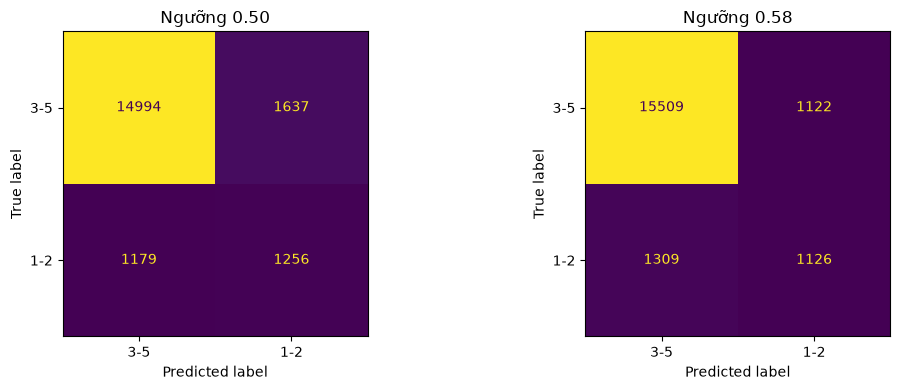


Permutation importance (mức giảm ROC-AUC khi xáo trộn feature):
item_count              0.0278
delivery_days           0.0255
delay_days              0.0199
is_late                 0.0043
estimated_days          0.0029
total_item_price        0.0018
total_freight           0.0018
total_paid              0.0017
seller_count            0.0015
distinct_products       0.0014
freight_to_price_pct    0.0010
customer_state          0.0009
purchase_hour           0.0008
max_installments        0.0007
purchase_month          0.0006
voucher_value           0.0001
same_state_item_pct     0.0001
first_payment_type      0.0000
payment_count          -0.0002
dtype: float64


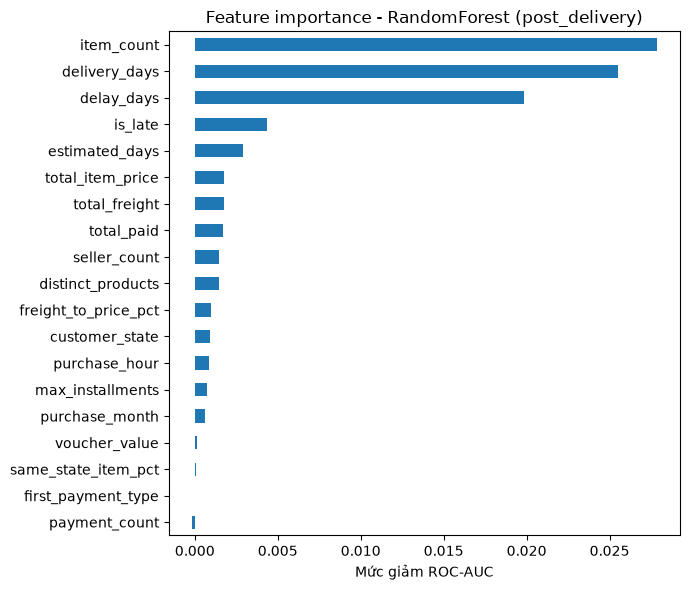

In [6]:
# 1. Chọn ngưỡng trên tập validation (tách từ train, KHÔNG dùng test để tránh nhìn trộm)
idx_tr2, idx_val = train_test_split(
    idx_train, test_size=0.2, stratify=y2.loc[idx_train], random_state=42)

rf = build_models(X_post)["RandomForest"]
rf.fit(X_post.loc[idx_tr2], y2.loc[idx_tr2])
p_val = rf.predict_proba(X_post.loc[idx_val])[:, 1]

thr_grid = np.arange(0.20, 0.81, 0.02)
scores = [f1_score(y2.loc[idx_val], (p_val >= t).astype(int), average="macro")
          for t in thr_grid]
best_thr = float(thr_grid[int(np.argmax(scores))])
print(f"Ngưỡng tốt nhất trên validation: {best_thr:.2f} "
      f"(macro-F1 val = {max(scores):.4f})")

# 2. Huấn luyện lại trên toàn bộ train, so sánh ngưỡng 0.5 và ngưỡng đã chọn trên test
rf = build_models(X_post)["RandomForest"]
rf.fit(X_post.loc[idx_train], y2.loc[idx_train])
p_test = rf.predict_proba(X_post.loc[idx_test])[:, 1]
yt = y2.loc[idx_test]

for thr in (0.5, best_thr):
    pred = (p_test >= thr).astype(int)
    print(f"\n===== Ngưỡng {thr:.2f} =====")
    print(classification_report(yt, pred, target_names=["Bình thường (3-5)", "Thấp (1-2)"],
                                digits=3))

# 3. Ma trận nhầm lẫn (confusion matrix) cho 2 ngưỡng
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, thr in zip(axes, (0.5, best_thr)):
    cm = confusion_matrix(yt, (p_test >= thr).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["3-5", "1-2"]).plot(
        ax=ax, colorbar=False, values_format="d")
    ax.set_title(f"Ngưỡng {thr:.2f}")
plt.tight_layout()
plt.show()

# 4. Mức quan trọng của feature (permutation importance, đo bằng ROC-AUC trên test)
perm = permutation_importance(
    rf, X_post.loc[idx_test], yt, scoring="roc_auc",
    n_repeats=5, random_state=42, n_jobs=-1)
imp = (pd.Series(perm.importances_mean, index=X_post.columns)
       .sort_values(ascending=False))
print("\nPermutation importance (mức giảm ROC-AUC khi xáo trộn feature):")
print(imp.round(4))

imp.sort_values().plot.barh(figsize=(7, 6))
plt.xlabel("Mức giảm ROC-AUC")
plt.title("Feature importance - RandomForest (post_delivery)")
plt.tight_layout()
plt.show()

## Bước 6. Tinh chỉnh tham số và loại bỏ feature yếu
Dùng `RandomizedSearchCV` (3-fold, tối ưu PR-AUC) trên tập train, rồi so sánh 3 cấu hình: Random Forest mặc định, đã tinh chỉnh, và đã tinh chỉnh sau khi bỏ 4 feature đóng góp gần bằng 0.

In [7]:
# 4 feature có mức quan trọng ~0 ở bước trước -> thử loại bỏ
weak = ["first_payment_type", "payment_count", "same_state_item_pct", "voucher_value"]
X_small = X_post.drop(columns=weak)

def make_rf(X, **params):
    # Pipeline Random Forest; tự bỏ qua cột phân loại nếu không có trong X
    cat = [c for c in ["customer_state", "first_payment_type"] if c in X.columns]
    num = [c for c in X.columns if c not in cat]
    transformers = [("num", "passthrough", num)]
    if cat:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat))
    pipe = Pipeline([
        ("pre", ColumnTransformer(transformers)),
        ("clf", RandomForestClassifier(class_weight="balanced_subsample",
                                       n_jobs=-1, random_state=42)),
    ])
    return pipe.set_params(**params)

# 1. Tìm tham số (chỉ trên train, 3-fold, tối ưu PR-AUC)
param_dist = {
    "clf__n_estimators": randint(200, 500),
    "clf__min_samples_leaf": randint(5, 60),
    "clf__max_depth": [None, 12, 16, 20],
    "clf__max_features": ["sqrt", 0.3, 0.5],
}
search = RandomizedSearchCV(
    make_rf(X_post), param_dist, n_iter=10, scoring="average_precision",
    cv=StratifiedKFold(3, shuffle=True, random_state=42),
    random_state=42, n_jobs=1, verbose=1)
search.fit(X_post.loc[idx_train], y2.loc[idx_train])
best = search.best_params_
print("Tham số tốt nhất:", best)
print("PR-AUC CV: %.4f" % search.best_score_)

# 2. So sánh 3 cấu hình: chọn ngưỡng trên validation, đo trên test
def evaluate(X, params, label):
    m = make_rf(X, **params)
    m.fit(X.loc[idx_tr2], y2.loc[idx_tr2])
    pv = m.predict_proba(X.loc[idx_val])[:, 1]
    grid = np.arange(0.20, 0.81, 0.02)
    thr = float(grid[int(np.argmax(
        [f1_score(y2.loc[idx_val], (pv >= t).astype(int), average="macro") for t in grid]))])
    m = make_rf(X, **params)
    m.fit(X.loc[idx_train], y2.loc[idx_train])
    pt = m.predict_proba(X.loc[idx_test])[:, 1]
    pred = (pt >= thr).astype(int)
    yt = y2.loc[idx_test]
    return dict(model=label, n_features=X.shape[1], thr=thr,
                roc_auc=roc_auc_score(yt, pt),
                pr_auc=average_precision_score(yt, pt),
                f1_low=f1_score(yt, pred),
                macro_f1=f1_score(yt, pred, average="macro"))

default = dict(clf__n_estimators=200, clf__min_samples_leaf=20)
rows = [
    evaluate(X_post,  default, "RF mặc định - đủ feature"),
    evaluate(X_post,  best,    "RF đã tune - đủ feature"),
    evaluate(X_small, best,    "RF đã tune - bỏ 4 feature yếu"),
]
pd.DataFrame(rows).round(4)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Tham số tốt nhất: {'clf__max_depth': 16, 'clf__max_features': 0.3, 'clf__min_samples_leaf': 32, 'clf__n_estimators': 387}
PR-AUC CV: 0.4650


,model,n_features,thr,roc_auc,pr_auc,f1_low,macro_f1
0,RF mặc định - đủ feature,19,0.58,0.7523,0.4765,0.4809,0.7041
1,RF đã tune - đủ feature,19,0.60,0.7540,0.4798,0.4830,0.7057
2,RF đã tune - bỏ 4 feature yếu,15,0.64,0.7546,0.4791,0.4812,0.7071


## Bước 7. Chốt mô hình, lưu file và dự đoán thử
Huấn luyện bản cuối (Random Forest đã tinh chỉnh, 15 feature) cho cả 2 kịch bản, lập bảng kết quả cuối, lưu mô hình bằng `joblib` và viết hàm dự đoán cho một đơn hàng mới.

In [8]:
# Tham số tốt nhất từ RandomizedSearchCV ở bước trước
best_params = {'clf__max_depth': 16, 'clf__max_features': 0.3,
               'clf__min_samples_leaf': 32, 'clf__n_estimators': 387}

def final_fit(X, label):
    # Trả về: mô hình đã train, ngưỡng, và dict kết quả trên test
    # Chọn ngưỡng trên validation
    m = make_rf(X, **best_params)
    m.fit(X.loc[idx_tr2], y2.loc[idx_tr2])
    pv = m.predict_proba(X.loc[idx_val])[:, 1]
    grid = np.arange(0.20, 0.81, 0.02)
    thr = float(grid[int(np.argmax(
        [f1_score(y2.loc[idx_val], (pv >= t).astype(int), average="macro") for t in grid]))])
    # Train lại trên toàn bộ train, đánh giá trên test
    m = make_rf(X, **best_params)
    m.fit(X.loc[idx_train], y2.loc[idx_train])
    pt = m.predict_proba(X.loc[idx_test])[:, 1]
    pred = (pt >= thr).astype(int)
    yt = y2.loc[idx_test]
    _, fp, fn, tp = confusion_matrix(yt, pred).ravel()
    res = dict(kich_ban=label, n_features=X.shape[1], nguong=thr,
               roc_auc=roc_auc_score(yt, pt),
               pr_auc=average_precision_score(yt, pt),
               precision_thap=tp / (tp + fp), recall_thap=tp / (tp + fn),
               f1_thap=f1_score(yt, pred), macro_f1=f1_score(yt, pred, average="macro"))
    return m, thr, res

# Bộ feature cuối cùng: bỏ 4 feature yếu
X_final_post = X_post.drop(columns=weak)
X_final_pre  = X_pre.drop(columns=[c for c in weak if c in X_pre.columns])

model_post, thr_post, r_post = final_fit(X_final_post, "Sau khi giao hàng (post_delivery)")
model_pre,  thr_pre,  r_pre  = final_fit(X_final_pre,  "Lúc đặt hàng (at_purchase)")

# Bảng tổng hợp kết quả cuối (kèm baseline để so sánh)
summary = pd.DataFrame([r_pre, r_post]).round(4)
summary.loc[len(summary)] = ["Baseline (luôn đoán 'bình thường')", None, None,
                             0.5, y2.loc[idx_test].mean(), 0, 0, 0, 0.4659]
display(summary)

# Lưu mô hình kèm ngưỡng và danh sách cột để dùng lại
joblib.dump({"model": model_post, "threshold": thr_post,
             "columns": list(X_final_post.columns)}, "review_model_post_delivery.joblib")
joblib.dump({"model": model_pre, "threshold": thr_pre,
             "columns": list(X_final_pre.columns)}, "review_model_at_purchase.joblib")
print("\nĐã lưu 2 file .joblib trong:", Path.cwd())

# Hàm dự đoán nguy cơ điểm thấp cho một đơn hàng mới
def predict_low_score(order_dict, bundle):
    row = pd.DataFrame([order_dict])[bundle["columns"]]
    p = bundle["model"].predict_proba(row)[0, 1]
    return {"xac_suat_diem_thap": round(float(p), 3),
            "canh_bao": bool(p >= bundle["threshold"])}

# Demo: dự đoán thử 3 đơn đầu của tập test
bundle = joblib.load("review_model_post_delivery.joblib")
demo = X_final_post.loc[idx_test].head(3)
for i, (idx, r) in enumerate(demo.iterrows()):
    print(f"Đơn {i+1} (điểm thật = {y5.loc[idx]}):",
          predict_low_score(r.to_dict(), bundle))

,kich_ban,n_features,nguong,roc_auc,pr_auc,precision_thap,recall_thap,f1_thap,macro_f1
0,Lúc đặt hàng (at_purchase),11.0,0.56,0.6475,0.258100,0.2827,0.3162,0.2985,0.5944
1,Sau khi giao hàng (post_delivery),15.0,0.64,0.7546,0.479100,0.5437,0.4316,0.4812,0.7071
2,Baseline (luôn đoán 'bình thường'),NaN,NaN,0.5000,0.127714,0.0000,0.0000,0.0000,0.4659



Đã lưu 2 file .joblib trong: d:\FPT UNIVERSITY\Kì 3\ADY201m\ADY291c-AI2107-Group2\Notebooks Project\6_Regression Analysis
Đơn 1 (điểm thật = 5): {'xac_suat_diem_thap': 0.294, 'canh_bao': False}
Đơn 2 (điểm thật = 5): {'xac_suat_diem_thap': 0.265, 'canh_bao': False}
Đơn 3 (điểm thật = 5): {'xac_suat_diem_thap': 0.279, 'canh_bao': False}


## Kết luận
| Kịch bản | ROC-AUC | PR-AUC | Precision (thấp) | Recall (thấp) | F1 (thấp) | Macro-F1 |
|---|---|---|---|---|---|---|
| Baseline (luôn đoán "bình thường") | 0,500 | 0,128 | 0 | 0 | 0 | 0,466 |
| Lúc đặt hàng (11 feature) | 0,648 | 0,258 | 0,283 | 0,316 | 0,299 | 0,594 |
| Sau giao hàng (15 feature) | 0,755 | 0,479 | 0,544 | 0,432 | 0,481 | 0,707 |

- Thông tin giao hàng là yếu tố tạo khác biệt lớn nhất: ROC-AUC tăng từ 0,648 lên 0,755 và PR-AUC từ 0,258 lên 0,479.
- Các feature quan trọng nhất: `item_count`, `delivery_days`, `delay_days`. Đây là mối liên hệ thống kê, chưa phải bằng chứng nhân quả.
- Tinh chỉnh tham số gần như không cải thiện thêm, bộ feature hiện tại đã gần đạt giới hạn.

**Hạn chế:**
- Mô hình sau giao hàng dùng thông tin biết sau khi giao nên chỉ phù hợp để giải thích hoặc cảnh báo muộn.
- Mô hình lúc đặt hàng còn yếu.
- Kết quả dựa trên một lần chia train/test.
- Xác suất đầu ra chưa được hiệu chuẩn, chỉ nên dùng để xếp hạng rủi ro.